# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [1]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
from google.colab import files

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [3]:
df = pd.read_csv("/content/Lab_11_QnA_Dataset.csv")
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())


Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [4]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [5]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [6]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

print("Training finished!")

Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

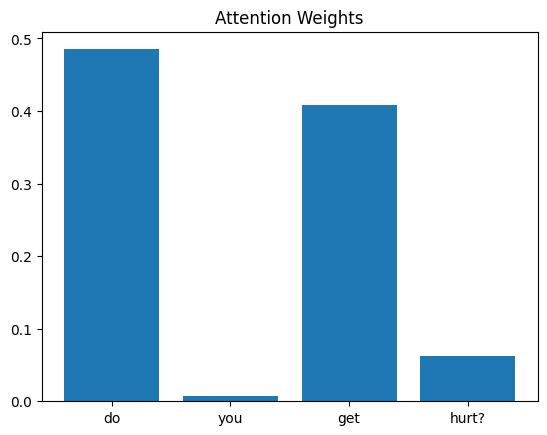

In [7]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

do you have fingers?      -> highest attention: 'do' (0.83)
who created you?          -> highest attention: 'who' (0.59)
what do you eat?          -> highest attention: 'eat' (0.53)


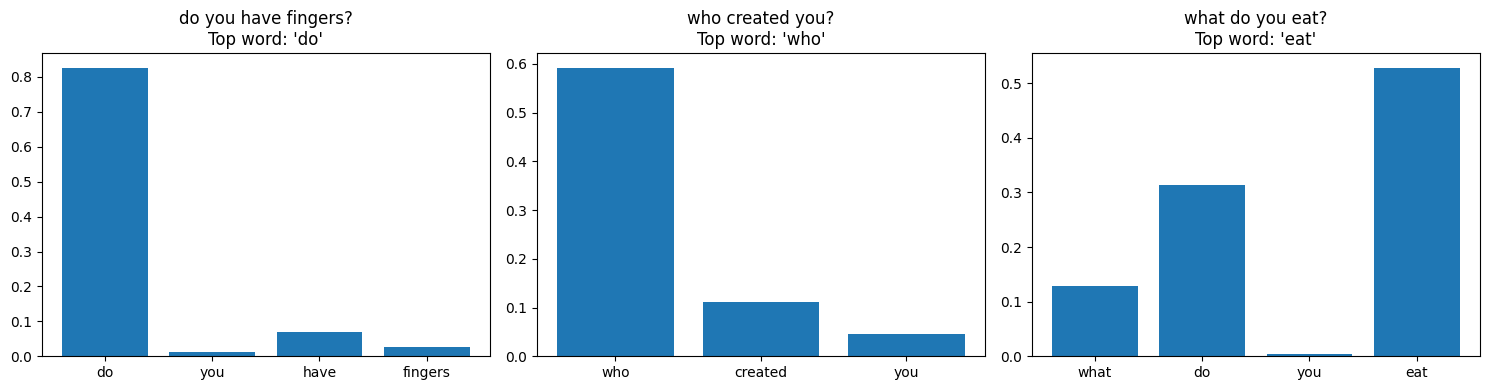

In [8]:
def plot_attention(i, ax=None):
    tokens = X[i][X[i] != 0].tolist()                 # drop padding
    words = [tokenizer.index_word[t] for t in tokens]  # clean words (no punctuation)
    with torch.no_grad():
        prediction, weights = model(X[i:i+1])
    w = weights[0, :len(words)].tolist()
    top = words[w.index(max(w))]
    ax = ax or plt.gca()
    ax.bar(words, w)
    ax.set_title(f"{df['question'][i]}\nTop word: '{top}'")
    print(f"{df['question'][i]:<25} -> highest attention: '{top}' ({max(w):.2f})")
    return top

# Task 1: three questions from different answer groups
idx = [df.index[df["question"] == q][0] for q in
       ["do you have fingers?", "who created you?", "what do you eat?"]]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for i, ax in zip(idx, axes):
    plot_attention(i, ax)
plt.tight_layout()
plt.show()

**Answer:**

| Question | Highest-attention word | Important? |
|---|---|---|
| do you have fingers? | `do` | ❌ No — "fingers" is the key word |
| who created you? | `who` | ⚠️ Partly — "created" carries the meaning |
| what do you eat? | `eat` | ✅ Yes — "eat" is the key word |

**Observation:** Only sometimes. The model attends to meaningful words in some questions (`eat`), but in others it picks generic words like `do` or `who`. These generic words are common at the start of questions in a specific answer group, so the model uses them as a shortcut rather than understanding the content word. Also, the model is small and trained for only 50 epochs, so its attention is not fully meaningful yet.

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

do you have a name?       -> highest attention: 'name' (0.92)
so what's your name?      -> highest attention: 'name' (0.57)


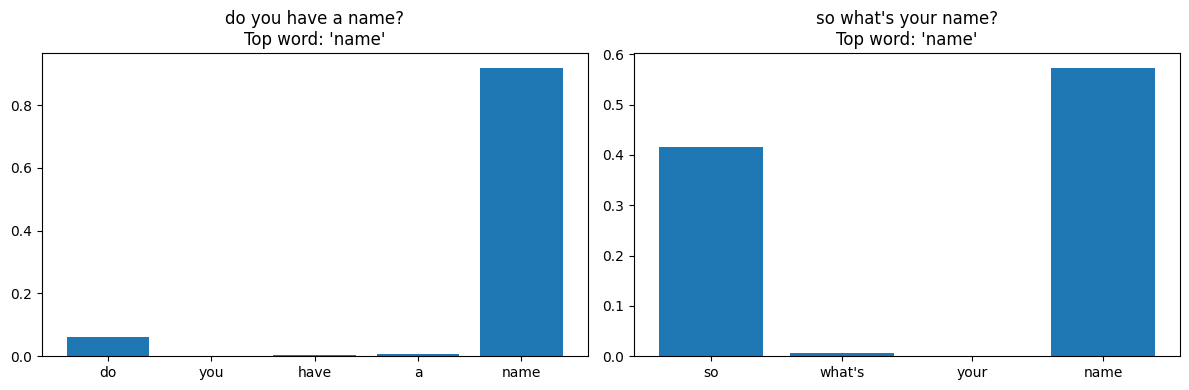

Same top word? True


In [9]:
q_a = df.index[df["question"] == "do you have a name?"][0]
q_b = df.index[df["question"] == "so what's your name?"][0]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
top_a = plot_attention(q_a, axes[0])
top_b = plot_attention(q_b, axes[1])
plt.tight_layout()
plt.show()

print("Same top word?", top_a == top_b)

**Answer:**

**Observation:** The model focuses on the **same word** even though the wording is different. Filler words like `do`, `have`, `a`, `so`, `what's`, `your` get very low weights.

**What this suggests:** Attention learns to pick out the **keywords that decide the answer** and ignore the rest of the sentence. If two questions share the same keyword, they get similar attention and similar outputs — wording does not matter much. But if similar questions use *different* keywords, the attention can land on different words, which shows the model learns word-level patterns, not true meaning.